<a href="https://colab.research.google.com/github/psh135230-design/BioAI_KU_2026/blob/main/%E1%84%87%E1%85%A1%E1%84%8B%E1%85%B5%E1%84%8B%E1%85%A9%E1%84%8B%E1%85%B5%E1%86%AB%E1%84%80%E1%85%A9%E1%86%BC%E1%84%8C%E1%85%B5%E1%84%82%E1%85%B3%E1%86%BC_10_29(%ED%94%BC%EB%93%9C%EB%B0%B1_%EC%88%98%EC%A0%95%EB%B3%B8).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [38]:
%pip install -q "pandas==2.2.3" "scanpy[leiden]==1.11.5"

In [39]:
import scanpy as sc
import pandas as pd

print("Scanpy:", sc.__version__)
print("Pandas:", pd.__version__)

Scanpy: 1.11.5
Pandas: 2.2.3


/tmp/ipykernel_1165/3927035035.py:4: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy:", sc.__version__)


In [40]:
import os

file_path = "/content/GSE154763_MYE_count.h5"

if os.path.exists(file_path):
    try:
        # .h5ad 대신 10x Genomics .h5 파일을 읽는 함수를 사용합니다.
        adata = sc.read_10x_h5(file_path)
        print("Successfully loaded original dataset:")
        print(adata)
    except Exception as e:
        print(f"Could not load file: {e}")
else:
    print(f"File not found at {file_path}. Please re-upload or re-download the dataset.")

Successfully loaded original dataset:
AnnData object with n_obs × n_vars = 7619 × 15634
    var: 'gene_ids'


In [41]:
print("Data shape:", adata.shape)

print("\nCell metadata:")
print(adata.obs.columns.tolist())

print("\nGene metadata:")
print(adata.var.columns.tolist())

print("\nSaved embeddings:")
print(list(adata.obsm.keys()))

print("\nSaved analyses:")
print(list(adata.uns.keys()))

Data shape: (7619, 15634)

Cell metadata:
[]

Gene metadata:
['gene_ids']

Saved embeddings:
[]

Saved analyses:
[]


In [42]:
adata.var_names_make_unique()

# astype(bool)을 추가하여 Pandas BooleanArray 대신 NumPy boolean 배열로 변환하여 저장합니다.
adata.var['mt'] = adata.var_names.str.startswith('MT-').astype(bool)

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=['mt'],
    percent_top=None,
    inplace=True
)

print(adata.obs[
    ['n_genes_by_counts', 'total_counts', 'pct_counts_mt']
].describe())

       n_genes_by_counts  total_counts  pct_counts_mt
count        7619.000000   7619.000000    7619.000000
mean         1961.669904   6754.211839       3.882464
std           679.841537   4072.257968       1.150013
min           690.000000   2003.000000       0.000000
25%          1447.000000   3987.000000       3.162361
50%          1876.000000   5801.000000       3.732599
75%          2332.000000   8124.500000       4.405609
max          4943.000000  38618.000000       9.976019


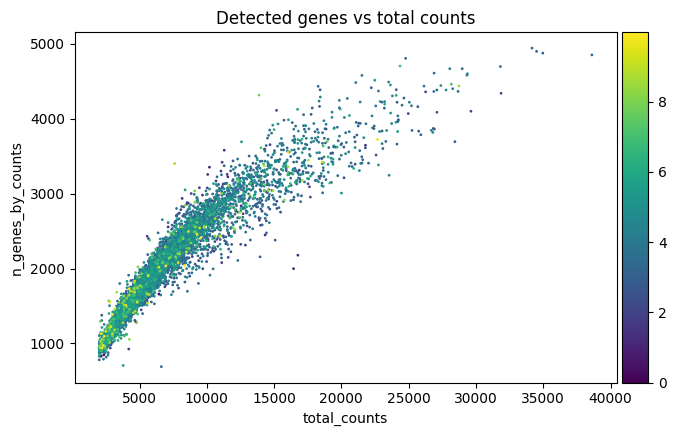

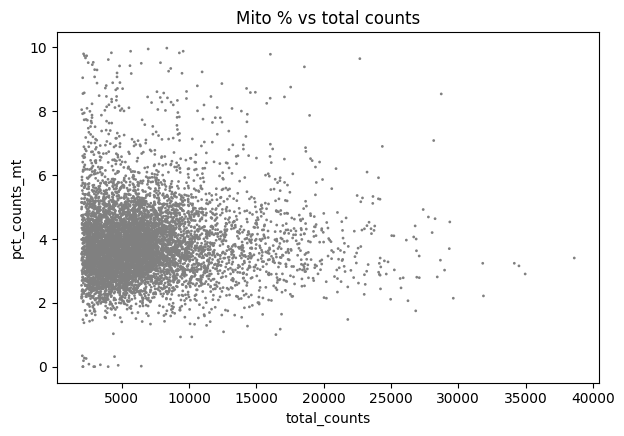

In [43]:
# 총 count vs 검출 유전자 수 (색 = 미토 비율)
sc.pl.scatter(adata, x='total_counts', y='n_genes_by_counts', color='pct_counts_mt',
              title='Detected genes vs total counts')

# 총 count vs 미토 비율
sc.pl.scatter(adata, x='total_counts', y='pct_counts_mt',
              title='Mito % vs total counts')

In [44]:
import numpy as np
from scipy import sparse

if sparse.issparse(adata.X):
    values = adata.X.data
else:
    values = np.asarray(adata.X).ravel()

print("Minimum:", values.min())
print("Maximum:", values.max())

# 모든 값이 정수인지 확인
print(
    "Integer counts:",
    np.allclose(values, np.round(values))
)

# 음수 존재 여부
print(
    "Non-negative:",
    np.all(values >= 0)
)

Minimum: 1.0
Maximum: 6140.0
Integer counts: True
Non-negative: True


In [45]:
# 원본 Count 데이터 보존
adata.layers["counts"] = adata.X.copy()

# 세포별 총 Count를 10,000으로 정규화
sc.pp.normalize_total(adata, target_sum=1e4)

# Log transformation
sc.pp.log1p(adata)

print(adata)

AnnData object with n_obs × n_vars = 7619 × 15634
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    uns: 'log1p'
    layers: 'counts'


In [46]:
import numpy as np

# Raw count 데이터
raw_counts = adata.layers["counts"]

# 정규화 및 로그 변환된 데이터
normalized_data = adata.X

print("Raw counts shape:", raw_counts.shape)
print("Normalized data shape:", normalized_data.shape)

print("\nLog transformation 정보:")
print(adata.uns.get("log1p"))

print("\nRaw data:")
print(raw_counts[:5, :5].toarray())

print("\nNormalized & Log-transformed data:")
print(normalized_data[:5, :5].toarray())

Raw counts shape: (7619, 15634)
Normalized data shape: (7619, 15634)

Log transformation 정보:
{'base': None}

Raw data:
[[0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 1. 0. 0. 0.]]

Normalized & Log-transformed data:
[[0.         0.7152578  0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.        ]
 [0.         1.11888233 0.         0.         0.        ]
 [0.         0.47150852 0.         0.         0.        ]]


Number of HVGs: 2000


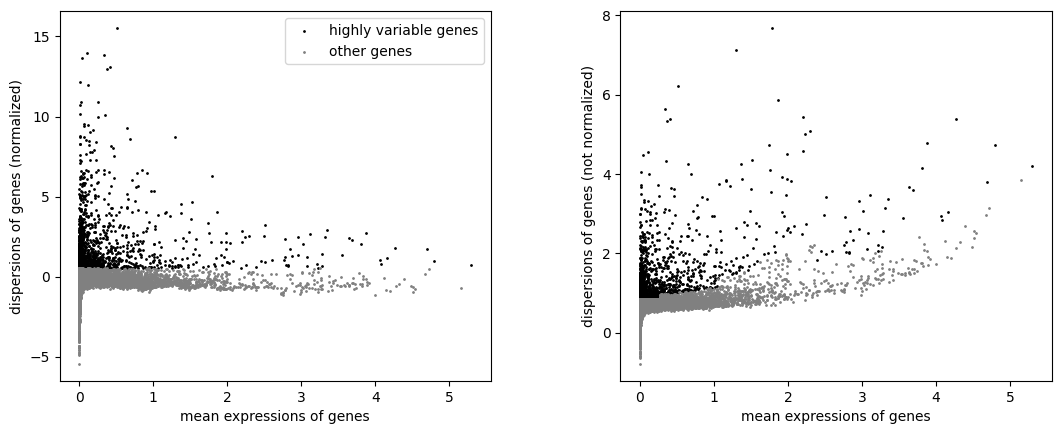

In [47]:
# HVG 2,000개 선정 (논문에서 STAR methods 분석할 때 HGV 2천 개 선정했다고 했음)
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor='seurat'
)

# 선정된 HVG 개수 확인
print(
    "Number of HVGs:",
    adata.var['highly_variable'].sum()
)

# HVG 시각화
sc.pl.highly_variable_genes(adata)

In [50]:
from sklearn.metrics import adjusted_rand_score
sc.tl.pca(adata, n_comps=50)
for n in [10, 20, 30, 50]:
    sc.pp.neighbors(adata, n_pcs=n, key_added=f'nn{n}')
    sc.tl.leiden(adata, neighbors_key=f'nn{n}', key_added=f'leiden_{n}')
    print(n, adata.obs[f'leiden_{n}'].nunique(), '개 클러스터')
print('30 vs 50 일치도(ARI):', adjusted_rand_score(adata.obs['leiden_30'], adata.obs['leiden_50']))

10 19 개 클러스터
20 17 개 클러스터
30 18 개 클러스터
50 18 개 클러스터
30 vs 50 일치도(ARI): 0.8201597352021124


30 14 개 클러스터
50 16 개 클러스터
ARI (res 0.6): 0.834
changed
same       6952
changed     667
Name: count, dtype: int64
leiden_50     0    1    2    3    4    5    6    7    8    9   10   11   12  \
leiden_30                                                                     
0          1470    0    9    0    1    0    0    0   23   14    0    0    0   
1             5  284  893    0    2    0    0    1    0    2    0    0    1   
2             0  874    0    0    4    0    0    0    0    0    0    0    0   
3             0    1    0  572    0    0    0    0    0    0    0    1    0   
4            32   21   15    0  539   12    0    1    0    1    0    0    0   
5             2    1    4    0    7  537    0    4    0    8    0    0    0   
6             0    0    0    1    0    0  544    0    0    0    0    0    0   
7             0    0   20    0    1    3    0  430    1    0    0    0    1   
8            12    0    2    0    3    3    0    0    2  242    0    0    0   
9             8   

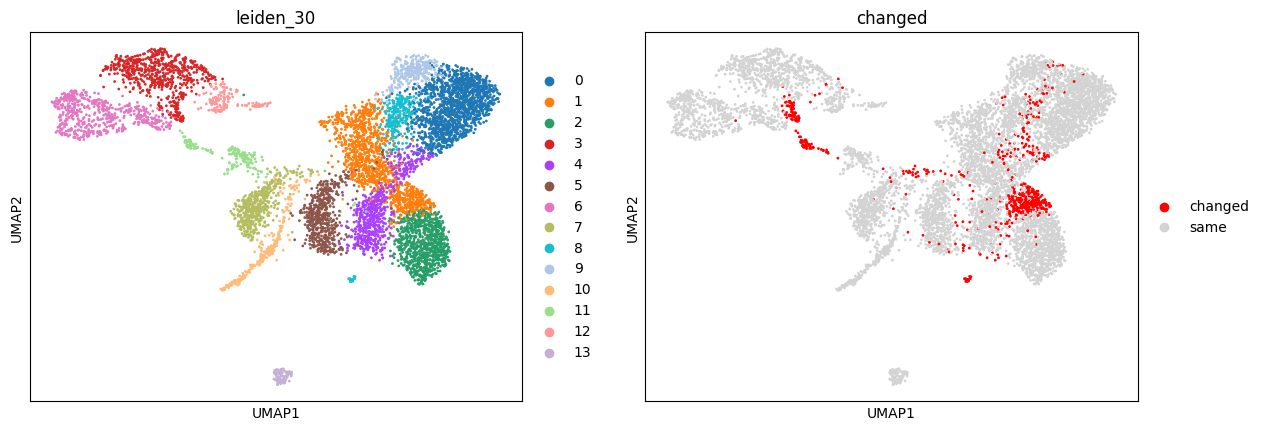

         n_genes_by_counts  total_counts
changed                                 
changed             1875.0        5759.0
same                1876.0        5809.5
changed  changed   same
sample                 
19         0.028  0.972
20         0.147  0.853
21         0.125  0.875
22         0.047  0.953
23         0.092  0.908
24         0.047  0.953
25         0.038  0.962
changed      changed  same
pred_type                 
Macro_C1QC       2.7  14.7
Macro_NLRP3      0.9   4.7
Mono_CD14       63.4  46.2
Mono_CD16       14.1  27.7
T_cell           1.2   0.1
cDC2            16.5   4.4
cDC3             1.0   0.1
pDC              0.1   2.1


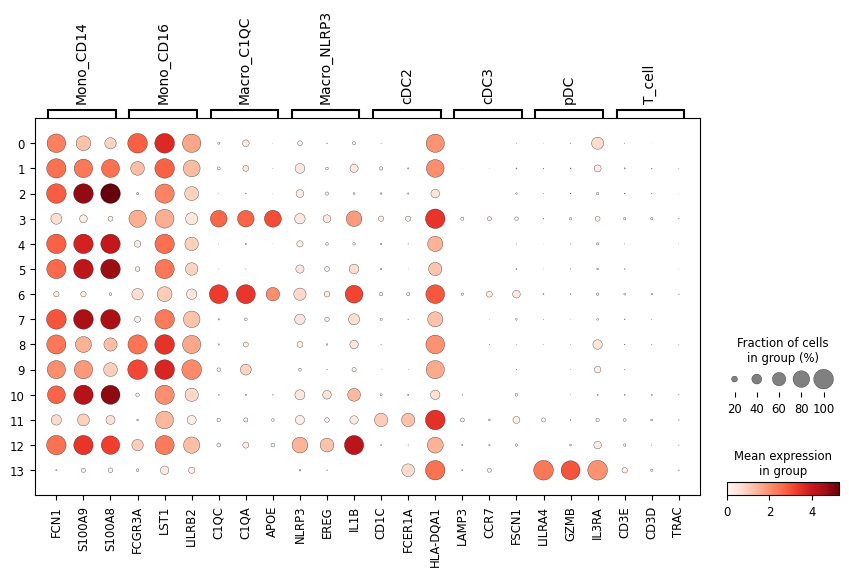


전체 7619개 세포 중 667개(8.8%)의 군집 배정이 바뀌었음.
군집 0: 주 세포형은 Mono_CD16임. 1524개 중 54개(4%)가 바뀌었고, 주로 PC50 군집 8로 옮겼음. 바뀐 세포는 Mono_CD16 85%, Mono_CD14 7%, Macro_C1QC 4%이고, 가장 많은 샘플은 23임.
군집 1: 주 세포형은 Mono_CD14임. 1188개 중 295개(25%)가 바뀌었고, 주로 PC50 군집 1로 옮겼음. 바뀐 세포는 Mono_CD14 97%, Mono_CD16 1%, cDC2 1%이고, 가장 많은 샘플은 20임.
군집 3: 주 세포형은 Macro_C1QC임. 640개 중 68개(11%)가 바뀌었고, 주로 PC50 군집 13로 옮겼음. 바뀐 세포는 cDC2 75%, Macro_C1QC 21%, Mono_CD14 3%이고, 가장 많은 샘플은 21임.
군집 4: 주 세포형은 Mono_CD14임. 621개 중 82개(13%)가 바뀌었고, 주로 PC50 군집 0로 옮겼음. 바뀐 세포는 Mono_CD14 74%, Mono_CD16 12%, cDC2 11%이고, 가장 많은 샘플은 22임.
군집 5: 주 세포형은 Mono_CD14임. 565개 중 28개(5%)가 바뀌었고, 주로 PC50 군집 9로 옮겼음. 바뀐 세포는 Mono_CD14 89%, cDC2 7%, Macro_NLRP3 4%이고, 가장 많은 샘플은 23임.
군집 7: 주 세포형은 Mono_CD14임. 456개 중 26개(6%)가 바뀌었고, 주로 PC50 군집 2로 옮겼음. 바뀐 세포는 Mono_CD14 81%, Mono_CD16 12%, Macro_NLRP3 4%이고, 가장 많은 샘플은 24임.
군집 8: 주 세포형은 Mono_CD16임. 281개 중 39개(14%)가 바뀌었고, 주로 PC50 군집 15로 옮겼음. 바뀐 세포는 Mono_CD16 62%, Mono_CD14 31%, cDC2 5%이고, 가장 많은 샘플은 23임.
군집 11: 주 세포형은 cDC2임. 175개 중 53개(3

In [56]:
import pandas as pd
from sklearn.metrics import adjusted_rand_score

# 1. PC30 / PC50 군집 (resolution 0.6, seed 0 = 10/13 주석과 같은 설정)
sc.tl.pca(adata, n_comps=50)
for n in [30, 50]:
    sc.pp.neighbors(adata, n_pcs=n, n_neighbors=15, key_added=f'nn{n}')
    sc.tl.leiden(adata, neighbors_key=f'nn{n}', resolution=0.6,
                 random_state=0, key_added=f'leiden_{n}')
    print(n, adata.obs[f'leiden_{n}'].nunique(), '개 클러스터')
print('ARI (res 0.6):', round(adjusted_rand_score(adata.obs['leiden_30'], adata.obs['leiden_50']), 3))

# 2. 바뀐 세포: PC30 군집마다 PC50에서 가장 많이 간 곳으로 안 간 세포
ct = pd.crosstab(adata.obs['leiden_30'], adata.obs['leiden_50'])
best = ct.idxmax(axis=1)
adata.obs['changed'] = ['changed' if b != best[a] else 'same'
                        for a, b in zip(adata.obs['leiden_30'], adata.obs['leiden_50'])]
print(adata.obs['changed'].value_counts())
print(ct)

# 3. UMAP
sc.tl.umap(adata, neighbors_key='nn30')
adata.uns['changed_colors'] = ['red', 'lightgrey']
sc.pl.umap(adata, color=['leiden_30', 'changed'], save='_changed_res06.png')

# 4. QC / 샘플
sc.pp.calculate_qc_metrics(adata, layer='counts', inplace=True)
print(adata.obs.groupby('changed', observed=True)[['n_genes_by_counts', 'total_counts']].median())
print(pd.crosstab(adata.obs['sample'], adata.obs['changed'], normalize='index').round(3))

# 5. 세포형 추정 (Cheng 2021 Fig 1E 마커)
markers = {
    'Mono_CD14':  ['FCN1', 'S100A9', 'S100A8'],
    'Mono_CD16':  ['FCGR3A', 'LST1', 'LILRB2'],
    'Macro_C1QC': ['C1QC', 'C1QA', 'APOE'],
    'Macro_NLRP3':['NLRP3', 'EREG', 'IL1B'],
    'cDC2':       ['CD1C', 'FCER1A', 'HLA-DQA1'],
    'cDC3':       ['LAMP3', 'CCR7', 'FSCN1'],
    'pDC':        ['LILRA4', 'GZMB', 'IL3RA'],
    'T_cell':     ['CD3E', 'CD3D', 'TRAC'],
}
markers = {k: [g for g in v if g in adata.var_names] for k, v in markers.items()}
for k, g in markers.items():
    sc.tl.score_genes(adata, g, score_name=f'score_{k}')
adata.obs['pred_type'] = adata.obs[[f'score_{k}' for k in markers]].idxmax(axis=1).str.replace('score_', '')
print((pd.crosstab(adata.obs['pred_type'], adata.obs['changed'], normalize='columns') * 100).round(1))
sc.pl.dotplot(adata, markers, groupby='leiden_30', save='_celltype_res06.png')

# 6. 글로 요약
obs = adata.obs
n_ch = (obs['changed'] == 'changed').sum()
print(f"\n전체 {len(obs)}개 세포 중 {n_ch}개({n_ch/len(obs)*100:.1f}%)의 군집 배정이 바뀌었음.")
for cl in sorted(obs['leiden_30'].unique(), key=int):
    sub = obs[obs['leiden_30'] == cl]
    chs = sub[sub['changed'] == 'changed']
    if len(chs) < 10:
        continue
    types = ', '.join(f"{k} {v:.0f}%" for k, v in (chs['pred_type'].value_counts(normalize=True) * 100).head(3).items())
    print(f"군집 {cl}: 주 세포형은 {sub['pred_type'].value_counts().idxmax()}임. "
          f"{len(sub)}개 중 {len(chs)}개({len(chs)/len(sub)*100:.0f}%)가 바뀌었고, 주로 PC50 군집 "
          f"{chs['leiden_50'].value_counts().idxmax()}로 옮겼음. 바뀐 세포는 {types}이고, "
          f"가장 많은 샘플은 {chs['sample'].value_counts().idxmax()}임.")

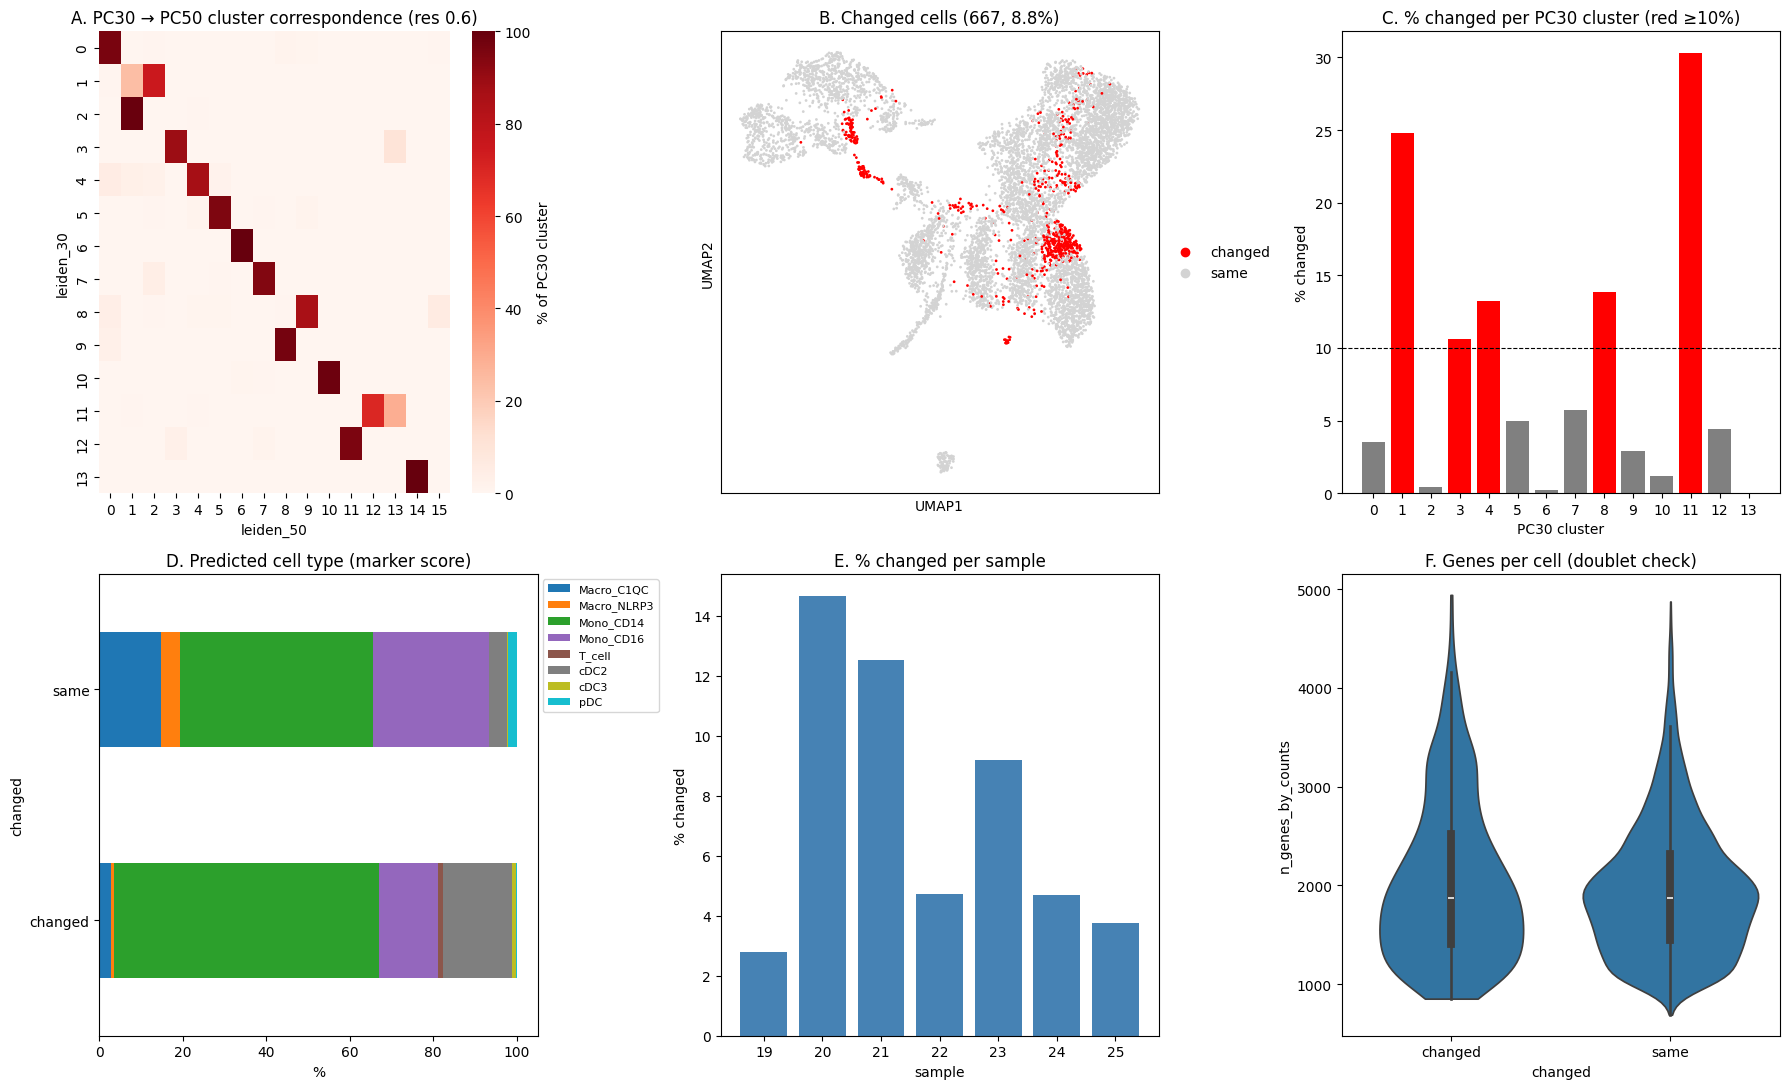

[A] 행마다 한 칸이 진할수록 PC30 군집이 PC50에서도 그대로 유지된 것임. 여러 칸에 나뉘면 군집이 쪼개지거나 합쳐진 것임.
[B] 전체 7619개 중 667개(8.8%)가 바뀌었음. 빨간 점이 몰린 곳이 불안정한 경계임.
[C] 변경 비율 10% 이상 군집: 11(30%), 1(25%), 8(14%), 4(13%), 3(11%).
[D] 바뀐 세포 세포형: Mono_CD14 63.4%(그대로 46.2%), cDC2 16.5%(그대로 4.4%), Mono_CD16 14.1%(그대로 27.7%), Macro_C1QC 2.7%(그대로 14.7%).
[E] 샘플별 변경 비율은 2.8~14.7%이고, 가장 높은 샘플은 20임.
[F] 유전자 수 중앙값은 바뀐 세포 1875, 그대로 1876임. 비슷하면 doublet 근거가 없음.
※ 세포형은 마커 점수로 추정한 값이라 확정 주석이 아님.


In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

obs = adata.obs
order30 = sorted(obs['leiden_30'].unique(), key=int)
fig, ax = plt.subplots(2, 3, figsize=(18, 11))

# A. 교차표 히트맵 (행 = PC30 군집, 각 행을 100%로)
ct = pd.crosstab(obs['leiden_30'], obs['leiden_50'], normalize='index') * 100
sns.heatmap(ct.loc[order30], cmap='Reds', vmin=0, vmax=100, ax=ax[0, 0], cbar_kws={'label': '% of PC30 cluster'})
ax[0, 0].set_title('A. PC30 → PC50 cluster correspondence (res 0.6)')

# B. UMAP: 바뀐 세포
sc.pl.umap(adata, color='changed', palette=['red', 'lightgrey'], ax=ax[0, 1], show=False,
           title=f"B. Changed cells ({(obs['changed']=='changed').sum()}, {(obs['changed']=='changed').mean()*100:.1f}%)")

# C. 군집별 변경 비율
rate = obs.groupby('leiden_30', observed=True)['changed'].apply(lambda x: (x == 'changed').mean() * 100).loc[order30]
ax[0, 2].bar(rate.index.astype(str), rate.values, color=['red' if v >= 10 else 'grey' for v in rate.values])
ax[0, 2].axhline(10, ls='--', c='k', lw=0.8)
ax[0, 2].set(title='C. % changed per PC30 cluster (red ≥10%)', xlabel='PC30 cluster', ylabel='% changed')

# D. 세포형 구성: 바뀐 vs 그대로
comp = pd.crosstab(obs['changed'], obs['pred_type'], normalize='index') * 100
comp.plot(kind='barh', stacked=True, ax=ax[1, 0], colormap='tab10', legend=False)
ax[1, 0].set(title='D. Predicted cell type (marker score)', xlabel='%')
ax[1, 0].legend(bbox_to_anchor=(1, 1), fontsize=8)

# E. 샘플별 변경 비율
srate = obs.groupby('sample', observed=True)['changed'].apply(lambda x: (x == 'changed').mean() * 100)
ax[1, 1].bar(srate.index.astype(str), srate.values, color='steelblue')
ax[1, 1].set(title='E. % changed per sample', xlabel='sample', ylabel='% changed')

# F. QC 비교
sns.violinplot(data=obs, x='changed', y='n_genes_by_counts', ax=ax[1, 2], cut=0)
ax[1, 2].set(title='F. Genes per cell (doublet check)')

plt.tight_layout()
plt.savefig('figures_1101/F_changed_summary_res06.png', dpi=200, bbox_inches='tight')
plt.show()

# ===== 자동 해설 =====
n_ch = (obs['changed'] == 'changed').sum()
hi = rate[rate >= 10]
c_comp = comp.loc['changed'].sort_values(ascending=False)
s_comp = comp.loc['same']
med = obs.groupby('changed', observed=True)['n_genes_by_counts'].median()
print("[A] 행마다 한 칸이 진할수록 PC30 군집이 PC50에서도 그대로 유지된 것임. 여러 칸에 나뉘면 군집이 쪼개지거나 합쳐진 것임.")
print(f"[B] 전체 {len(obs)}개 중 {n_ch}개({n_ch/len(obs)*100:.1f}%)가 바뀌었음. 빨간 점이 몰린 곳이 불안정한 경계임.")
print(f"[C] 변경 비율 10% 이상 군집: " + ', '.join(f"{k}({v:.0f}%)" for k, v in hi.sort_values(ascending=False).items()) + ".")
print("[D] 바뀐 세포 세포형: " + ', '.join(f"{k} {v:.1f}%(그대로 {s_comp[k]:.1f}%)" for k, v in c_comp.head(4).items()) + ".")
print(f"[E] 샘플별 변경 비율은 {srate.min():.1f}~{srate.max():.1f}%이고, 가장 높은 샘플은 {srate.idxmax()}임.")
print(f"[F] 유전자 수 중앙값은 바뀐 세포 {med['changed']:.0f}, 그대로 {med['same']:.0f}임. 비슷하면 doublet 근거가 없음.")
print("※ 세포형은 마커 점수로 추정한 값이라 확정 주석이 아님.")

PCA shape: (7619, 30)


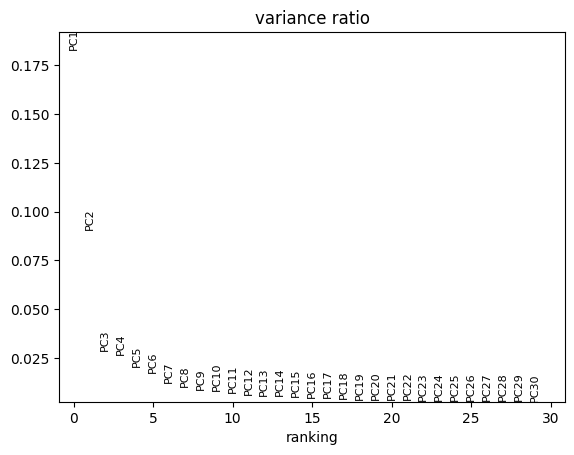

,주성분 (PC),설명 분산 비율 (%),누적 설명 분산 비율 (%)
0,PC1,18.28,18.28
1,PC2,9.05,27.33
2,PC3,2.86,30.19
3,PC4,2.68,32.87
4,PC5,2.04,34.91


In [ ]:
# HVG 2,000개를 이용한 PCA
sc.tl.pca(
    adata,
    n_comps=30,
    mask_var='highly_variable',
    svd_solver='arpack'
)

# PCA 결과 확인
print("PCA shape:", adata.obsm['X_pca'].shape)


# 설명 분산 비율 시각화
sc.pl.pca_variance_ratio(
    adata,
    n_pcs=30,
    log=False
)

variance_ratio = adata.uns["pca"]["variance_ratio"][:5]
pcs = [f"PC{i+1}" for i in range(len(variance_ratio))]
explained_pct = variance_ratio * 100
cumulative_pct = np.cumsum(explained_pct)

pca_summary_df = pd.DataFrame(
    {
        "주성분 (PC)": pcs,
        "설명 분산 비율 (%)": np.round(explained_pct, 2),
        "누적 설명 분산 비율 (%)": np.round(cumulative_pct, 2),
    }
)

# 표 출력
pd.set_option("display.max_rows", 30)
display(pca_summary_df)

In [59]:
import numpy as np, pandas as pd, scanpy as sc, matplotlib.pyplot as plt

# 'leiden' 대신 정의된 'leiden_30' 컬럼의 고유 클러스터 개수를 출력합니다.
if 'leiden_30' in adata.obs:
    print(f"leiden_30 클러스터 개수: {adata.obs['leiden_30'].nunique()}개 (14개가 정상)")
elif 'leiden' in adata.obs:
    print(f"leiden 클러스터 개수: {adata.obs['leiden'].nunique()}개")
else:
    print("경고: 'leiden_30' 또는 'leiden' 클러스터 정보가 adata.obs에 없습니다.")

print("'counts' 레이어 보존 여부:", 'counts' in adata.layers)
# 'counts'가 없는(False) 경우: 노트북 맨 위 normalize_total 직전에 adata.layers['counts'] = adata.X.copy() 넣고 다시 실행

leiden_30 클러스터 개수: 14개 (14개가 정상)
'counts' 레이어 보존 여부: True


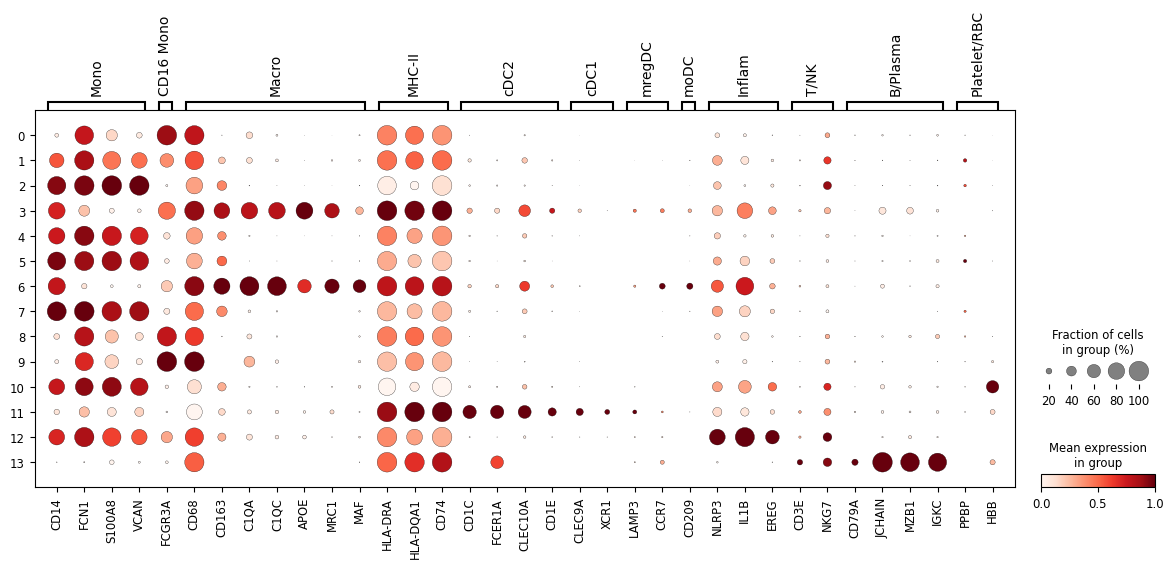

    C1QC  APOE  MRC1  CD163  CD1C  FCER1A  CLEC10A  CLEC9A  JCHAIN  MZB1
3   80.0  82.0  67.0   75.0  18.0    17.0     50.0    10.0    26.0  24.0
6   94.0  61.0  66.0   77.0  10.0     9.0     41.0     2.0    12.0   1.0
11  10.0   7.0  13.0   24.0  60.0    60.0     58.0    26.0     7.0   5.0


/tmp/ipykernel_1165/2735111104.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  columns=genes, index=sub.obs_names).groupby(sub.obs['leiden_30'].values).mean()*100


In [61]:
markers = {
    'Mono':      ['CD14', 'FCN1', 'S100A8', 'VCAN'],
    'CD16 Mono': ['FCGR3A'],
    'Macro':     ['CD68', 'CD163', 'C1QA', 'C1QC', 'APOE', 'MRC1', 'MAF'],
    'MHC-II':    ['HLA-DRA', 'HLA-DQA1', 'CD74'],
    'cDC2':      ['CD1C', 'FCER1A', 'CLEC10A', 'CD1E'],
    'cDC1':      ['CLEC9A', 'XCR1'],
    'mregDC':    ['LAMP3', 'CCR7'],
    'moDC':      ['CD209'],
    'Inflam':    ['NLRP3', 'IL1B', 'EREG'],
    'T/NK':      ['CD3E', 'NKG7'],
    'B/Plasma':  ['CD79A', 'JCHAIN', 'MZB1', 'IGKC'],
    'Platelet/RBC': ['PPBP', 'HBB'],
}
# groupby 컬럼을 기존 'leiden'에서 실제 존재하는 'leiden_30'으로 변경합니다.
sc.pl.dotplot(adata, markers, groupby='leiden_30', standard_scale='var', cmap='Reds',
              save='_F3_ambiguous_multimarker.png')

# 군집 3, 6, 11의 발현 세포 비율(%) 표로 확인 (leiden -> leiden_30)
genes = ['C1QC','APOE','MRC1','CD163','CD1C','FCER1A','CLEC10A','CLEC9A','JCHAIN','MZB1']
sub = adata[adata.obs['leiden_30'].isin(['3','6','11']), genes]
pct = pd.DataFrame((sub.X > 0).toarray() if hasattr(sub.X,'toarray') else (sub.X > 0),
                   columns=genes, index=sub.obs_names).groupby(sub.obs['leiden_30'].values).mean()*100
print(pct.round(0))

전체 doublet 비율: 0.8531303320645753


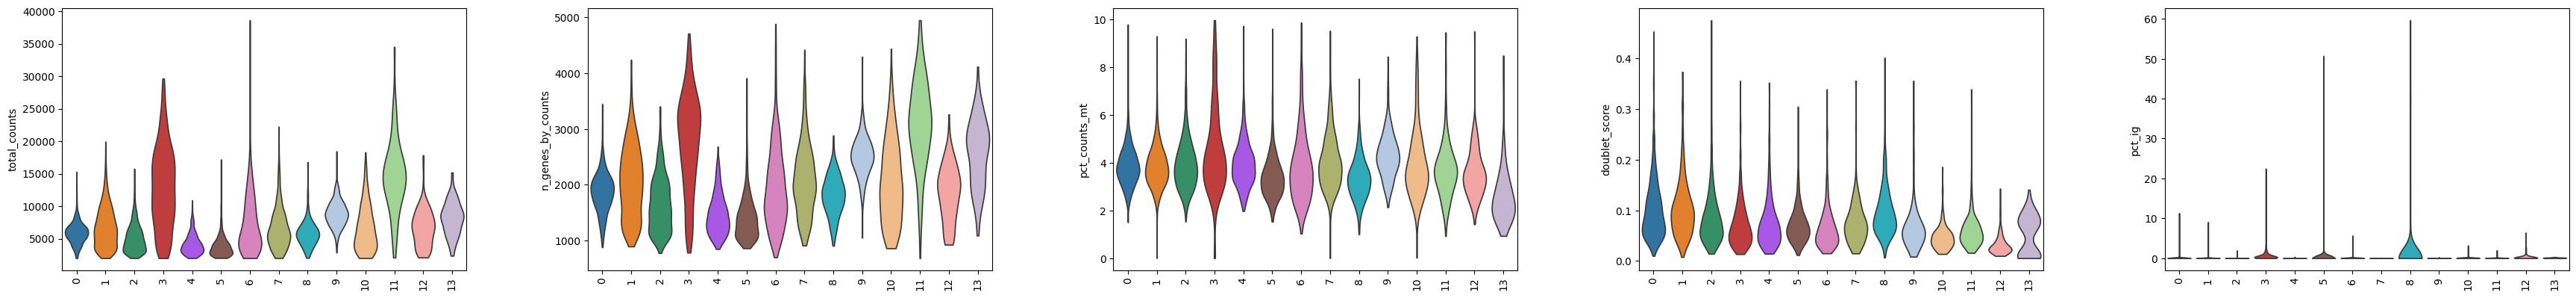

           total_counts  n_genes_by_counts  pct_counts_mt  doublet_score  \
leiden_30                                                                  
0                5854.5             1876.0           3.79           0.09   
1                6345.0             2035.0           3.76           0.10   
2                4661.5             1613.0           3.81           0.07   
3               12602.0             2870.5           4.15           0.06   
4                3865.0             1418.0           3.84           0.06   
5                3513.0             1338.0           3.28           0.06   
6                6105.0             1827.0           3.57           0.05   
7                5968.5             2022.0           3.91           0.07   
8                5702.0             1818.0           3.30           0.09   
9                8754.0             2506.0           4.25           0.06   
10               5936.0             1946.0           3.64           0.04   
11          

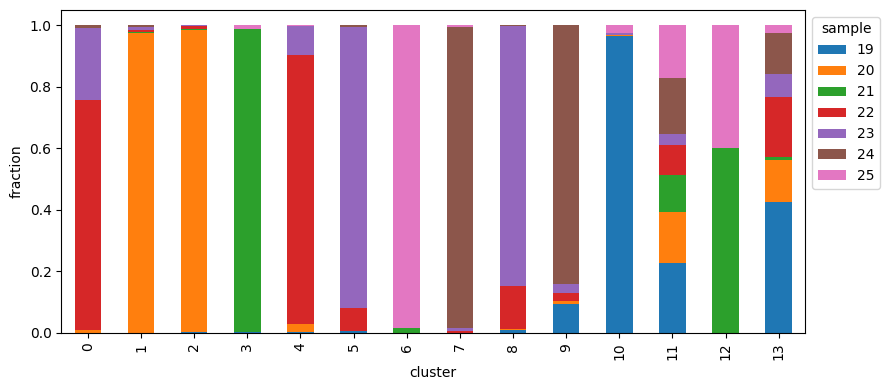

In [64]:
# (1) Scrublet: raw count로, 샘플별로 따로
tmp = sc.AnnData(adata.layers['counts'].copy(), obs=adata.obs[['sample']].copy())
sc.pp.scrublet(tmp, batch_key='sample', random_state=0)
adata.obs['doublet_score'] = tmp.obs['doublet_score'].values
adata.obs['predicted_doublet'] = tmp.obs['predicted_doublet'].values
print('전체 doublet 비율:', adata.obs['predicted_doublet'].mean()*100)

# (2) Ig 유전자 비율
ig = np.asarray(adata.var_names.str.match(r'^IG[HKL][VCJ]'), dtype=bool)
adata.obs['pct_ig'] = np.asarray(adata.layers['counts'][:, ig].sum(1)).ravel() / adata.obs['total_counts'] * 100

# (3) 군집별 QC violin (leiden_30으로 변경)
sc.pl.violin(adata, ['total_counts','n_genes_by_counts','pct_counts_mt','doublet_score','pct_ig'],
             groupby='leiden_30', rotation=90, stripplot=False, save='_F4_qc_doublet_by_cluster.png')

# (4) 군집별 QC 요약표 (leiden_30으로 변경, observed=True 추가)
g = adata.obs.groupby('leiden_30', observed=True)
qc = g[['total_counts','n_genes_by_counts','pct_counts_mt','doublet_score']].median()
qc['predicted_doublet_%'] = g['predicted_doublet'].mean()*100
qc['Ig>1%_세포_%'] = g['pct_ig'].apply(lambda s: (s > 1).mean()*100)
qc.round(2).to_csv('figures_1101/T2_qc_doublet_by_cluster.csv'); print(qc.round(2))

# (5) 군집별 샘플 구성 (leiden_30으로 변경)
comp = pd.crosstab(adata.obs['leiden_30'], adata.obs['sample'])
comp.to_csv('figures_1101/T3_cluster_by_sample.csv'); print(comp)
comp.div(comp.sum(1), axis=0).plot(kind='bar', stacked=True, figsize=(9,4))
plt.ylabel('fraction'); plt.xlabel('cluster'); plt.legend(title='sample', bbox_to_anchor=(1,1))
plt.tight_layout(); plt.savefig('figures_1101/F5_cluster_sample_composition.png', dpi=200)

# (6) 성별 유전자로 3과 6이 다른 환자인지 확인 (leiden_30으로 변경, observed=True 추가)
for gname in ['XIST','DDX3Y','RPS4Y1']:
    if gname in adata.var_names:
        print(gname, (adata[:, gname].X > 0).toarray().ravel().__class__ and
              adata.obs.assign(e=(adata[:, gname].X > 0).toarray().ravel())
              .groupby('leiden_30', observed=True)['e'].mean().loc[['3','6','11']].round(2).to_dict())

In [65]:
import re
stress = ['FOS','FOSB','JUN','JUNB','EGR1','DUSP1','IER2','IER3','HSPA1A','HSPA1B','HSP90AA1']
hvg = adata.var_names[adata.var['highly_variable']]
print('HVG 안 스트레스 유전자:', [g for g in stress if g in hvg])
print('HVG 안 Ig 유전자 수:', hvg.str.match(r'^IG[HKL][VCJ]').sum())
print('HVG 안 리보솜 유전자 수:', hvg.str.match(r'^RP[LS]').sum())

HVG 안 스트레스 유전자: ['FOS', 'FOSB', 'JUN', 'JUNB', 'EGR1', 'DUSP1', 'IER2', 'IER3', 'HSPA1A', 'HSPA1B', 'HSP90AA1']
HVG 안 Ig 유전자 수: 34
HVG 안 리보솜 유전자 수: 1


In [68]:
import re
filter_v1 = re.compile(r'^(RPL|RPS|MT-|IG[HKL][VCJ]|FOS|JUN|DUSP1|IER|HSPA|HSPH|HSP90)')
filter_v2 = re.compile(r'^(RPL|RPS|MT-|IG[HKL][VCJ]|FOS|JUN|DUSP1|IER|EGR1|HSPA|HSPH|HSP90)')

sc.tl.rank_genes_groups(adata, 'leiden_30', method='wilcoxon', key_added='wx', use_raw=False)

rows = []
for c in adata.obs['leiden_30'].cat.categories:
    df = sc.get.rank_genes_groups_df(adata, c, key='wx')
    v1 = [g for g in df['names'] if not filter_v1.match(g)][:10]
    v2 = [g for g in df['names'] if not filter_v2.match(g)][:10]
    removed = [g for g in v1 if g not in v2]
    rows.append({
        'Cluster': c,
        'n_cells': int((adata.obs['leiden_30'] == c).sum()),
        'Top 10 markers (revised filter)': ', '.join(v2),
        'Removed by revision': ', '.join(removed) if removed else '–',
        'Newly included': ', '.join([g for g in v2 if g not in v1]) or '–',
    })
tbl = pd.DataFrame(rows).set_index('Cluster')
tbl.to_csv('figures_1101/T6_top_markers_revised_filter.csv')
pd.set_option('display.max_colwidth', None)
tbl

,n_cells,Top 10 markers (revised filter),Removed by revision,Newly included
Cluster,,,,
0,1524,"LST1, IFITM2, FCGR3A, IFITM3, FCER1G, RHOC, HLA-C, AIF1, COTL1, LY6E",–,–
1,1188,"LGALS2, HLA-DRB1, LILRB1, PRELID1, CD52, DDIT4, PPDPF, ADGRE5, KLF2, FAM26F",–,–
2,878,"S100A8, S100A9, S100A12, GAPDH, VCAN, LYZ, VIM, S100A6, PLBD1, SERPINB1",–,–
3,640,"HLA-DRA, CD74, HLA-DRB1, HLA-DPB1, HLA-DMA, HLA-DQA1, OLR1, ZNF331, CD83, LITAF",–,–
4,621,"LYZ, S100A9, S100A8, TMEM176A, CSTA, AC090498.1, TMEM176B, MNDA, SH3BGRL3, S100A4",–,–
5,565,"CEBPD, S100A8, S100A9, LYZ, VCAN, BTG2, CSTA, S100A12, TMEM176A, CD14",EGR1,CD14
6,545,"CD83, CXCL8, LMNA, PPP1R15A, CCL4L2, CTSZ, C1QC, C1QA, GADD45B, NFKBIA",–,–
7,456,"KLF6, LINC00936, S100A9, MCL1, NCF1, CD44, CSF3R, LYZ, VCAN, BRI3",–,–
8,281,"RHOB, IFITM3, IFITM2, SAT1, KLF2, LST1, NR4A1, IFITM1, BTG2, FCGR3A",EGR1,FCGR3A


In [69]:
sc.tl.rank_genes_groups(adata, 'leiden_30', method='t-test',   key_added='tt', use_raw=False)
sc.tl.rank_genes_groups(adata, 'leiden_30', method='wilcoxon', key_added='wx', use_raw=False)

def top10(key, c):
    names = sc.get.rank_genes_groups_df(adata, c, key=key)['names']
    return [g for g in names if not filter_v2.match(g)][:10]

rows = []
for c in adata.obs['leiden_30'].cat.categories:
    t, w = top10('tt', c), top10('wx', c)
    rows.append({'Cluster': c,
                 'Overlap (of 10)': len(set(t) & set(w)),
                 't-test top 10': ', '.join(t),
                 'Wilcoxon top 10': ', '.join(w),
                 't-test only': ', '.join([g for g in t if g not in w]) or '–',
                 'Wilcoxon only': ', '.join([g for g in w if g not in t]) or '–'})
de = pd.DataFrame(rows).set_index('Cluster')
de.to_csv('figures_1101/T4_DE_ttest_vs_wilcoxon.csv')
pd.set_option('display.max_colwidth', None)
print('평균 겹침:', round(de['Overlap (of 10)'].mean(), 1))
de[['Overlap (of 10)', 't-test only', 'Wilcoxon only']]

평균 겹침: 8.3


,Overlap (of 10),t-test only,Wilcoxon only
Cluster,,,
0,10,–,–
1,10,–,–
2,8,"TSPO, S100A10","PLBD1, SERPINB1"
3,8,"HLA-DPA1, HLA-DQB1","OLR1, ZNF331"
4,7,"S100A6, FCN1, VCAN","TMEM176A, CSTA, MNDA"
5,8,"S100A4, S100A6","BTG2, TMEM176A"
6,9,C1QB,CCL4L2
7,8,"S100A8, FCN1","CD44, CSF3R"
8,8,"LY6E, COTL1","NR4A1, BTG2"


In [70]:
res = {}
for m in ['t-test', 'wilcoxon']:
    sc.tl.rank_genes_groups(adata, 'leiden_30', groups=['3'], reference='6',
                            method=m, key_added=f'3v6_{m}', use_raw=False)
    df = sc.get.rank_genes_groups_df(adata, '3', key=f'3v6_{m}')
    df = df[~df['names'].str.match(filter_v2.pattern)]
    res[m] = df

cmp = pd.DataFrame({
    'Higher in C3 (t-test)':   res['t-test']['names'].head(10).values,
    'Higher in C3 (Wilcoxon)': res['wilcoxon']['names'].head(10).values,
    'Higher in C6 (t-test)':   res['t-test']['names'].tail(10).values[::-1],
    'Higher in C6 (Wilcoxon)': res['wilcoxon']['names'].tail(10).values[::-1],
}, index=range(1, 11))
cmp.to_csv('figures_1101/T4b_C3_vs_C6.csv')
cmp

,Higher in C3 (t-test),Higher in C3 (Wilcoxon),Higher in C6 (t-test),Higher in C6 (Wilcoxon)
1,SERPINA1,SERPINA1,HLA-DRB5,HLA-DRB5
2,OLR1,HLA-A,CXCL8,CTSZ
3,LYZ,LYZ,CTSZ,CXCL8
4,SDS,GPX1,SEPP1,NFKBIZ
5,PSME2,CTSH,RNASE1,SEPP1
6,CTSH,OLR1,NFKBIZ,RNASE1
7,RGS2,PSME2,UBE2S,CCL4L2
8,GPX1,SDS,CCL4L2,LMNA
9,HLA-A,RGS2,LMNA,UBE2S
10,DDX3Y,FAM26F,XIST,PNRC1


In [ ]:
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30
)

sc.tl.umap(
    adata,
    random_state=0
)

sc.tl.leiden(
    adata,
    resolution=0.6,
    key_added='leiden',
    random_state=0
)

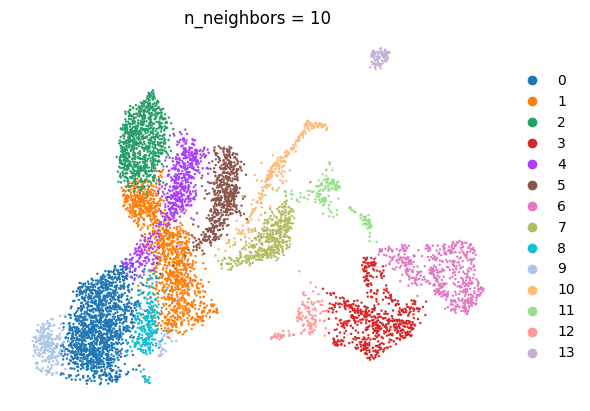

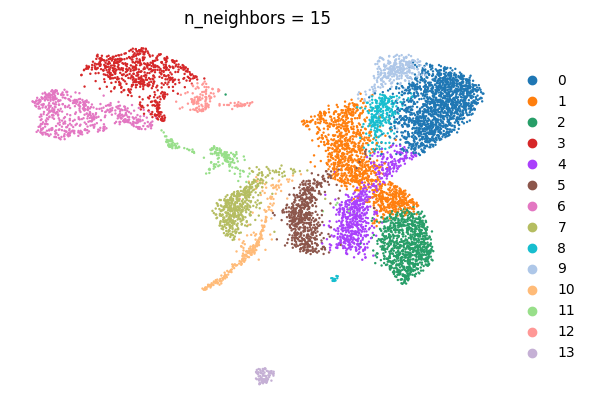

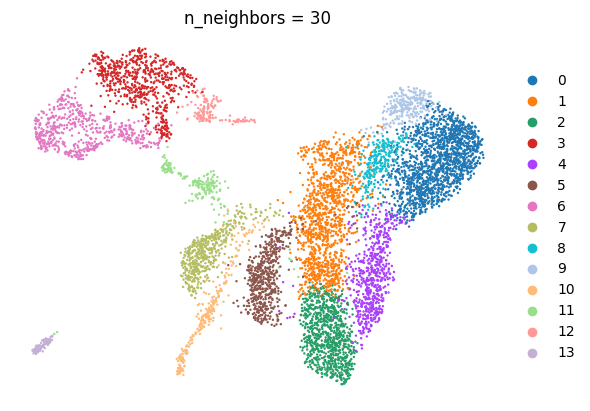

In [ ]:
# 클러스터별 UMAP 시각화

# 재현성을 위한 난수 시드 고정
RANDOM_STATE = 0

# k (n_neighbors) 값별로 UMAP을 계산하여 개별 출력
for k in [10, 15, 30]:
    tmp = adata.copy()  # 원본 adata 보호를 위해 복사본 사용
    sc.pp.neighbors(tmp, n_neighbors=k, random_state=RANDOM_STATE)
    sc.tl.umap(tmp, random_state=RANDOM_STATE)
    sc.pl.umap(
        tmp,
        color="leiden",  # 확인하고 싶은 obs 컬럼명
        size=12,
        title=f"n_neighbors = {k}",
        show=True,
        frameon=False
    )

In [ ]:
import scanpy as sc
import pandas as pd

# 각 클러스터의 Marker Gene 분석
sc.tl.rank_genes_groups(
    adata,
    groupby='leiden',
    method='t-test',
    use_raw=False,
    pts=True
)

print("Marker Gene Analysis is done")

Marker Gene Analysis is done


In [ ]:
# 각 클러스터별 상위 7개 Marker Gene 추출

results = []

for cluster in adata.obs['leiden'].cat.categories:

    df = sc.get.rank_genes_groups_df(
        adata,
        group=cluster
    )

    # 유의한 Marker Gene 선정
    df = df[
        (df['pvals_adj'] < 0.05) &
        (df['logfoldchanges'] > 0.25)
    ]

    top_genes = df['names'].head(7).tolist()

    results.append({
        'Cluster': cluster,
        'Top Marker Genes': ', '.join(top_genes)
    })

marker_summary = pd.DataFrame(results)

display(marker_summary)

,Cluster,Top Marker Genes
0,0,"IFITM2, FCGR3A, LST1, IFITM3, FCER1G, LY6E, AIF1"
1,1,"RPS26, HLA-DRB1, CD52, PRELID1, LGALS2, RPS3A,..."
2,2,"S100A8, S100A9, LYZ, VCAN, RPS26, S100A12, GAPDH"
3,3,"CD74, HLA-DRA, HLA-DRB1, HLA-DPB1, HLA-DMA, IG..."
4,4,"LYZ, RPL39, S100A8, S100A4, S100A9, S100A6, RPL34"
5,5,"FOS, S100A8, LYZ, IER2, S100A9, CEBPD, DUSP1"
6,6,"IER3, CD83, C1QC, C1QA, C1QB, FOSB, NFKBIA"
7,7,"FOS, LYZ, S100A9, S100A8, DUSP1, KLF6, VCAN"
8,8,"IFITM3, IFITM2, LST1, DUSP1, FCGR3A, RHOB, JUNB"
9,9,"FCGR3A, LST1, LINC01272, RPS19, IFITM2, SERPIN..."


In [ ]:
import re
bad = re.compile(r'^(RPL|RPS|MT-|IGLV|IGKV|IGHV|IGLC|IGKC|FOS|JUN|DUSP1|IER)')
for c in adata.obs['leiden'].cat.categories:
    g = sc.get.rank_genes_groups_df(adata, group=c)['names']
    print(c, [x for x in g if not bad.match(x)][:7])

0 ['IFITM2', 'FCGR3A', 'LST1', 'IFITM3', 'FCER1G', 'LY6E', 'AIF1']
1 ['HLA-DRB1', 'CD52', 'PRELID1', 'LGALS2', 'LILRB1', 'DDIT4', 'KLF2']
2 ['S100A8', 'S100A9', 'LYZ', 'VCAN', 'S100A12', 'GAPDH', 'S100A6']
3 ['CD74', 'HLA-DRA', 'HLA-DRB1', 'HLA-DPB1', 'HLA-DMA', 'HLA-DQA1', 'HLA-DPA1']
4 ['LYZ', 'S100A8', 'S100A4', 'S100A9', 'S100A6', 'FCN1', 'AC090498.1']
5 ['S100A8', 'LYZ', 'S100A9', 'CEBPD', 'EGR1', 'VCAN', 'S100A4']
6 ['CD83', 'C1QC', 'C1QA', 'C1QB', 'NFKBIA', 'CXCL8', 'PPP1R15A']
7 ['LYZ', 'S100A9', 'S100A8', 'KLF6', 'VCAN', 'MCL1', 'FCN1']
8 ['IFITM3', 'IFITM2', 'LST1', 'FCGR3A', 'RHOB', 'KLF2', 'EGR1']
9 ['FCGR3A', 'LST1', 'LINC01272', 'IFITM2', 'SERPINA1', 'LILRB2', 'CORO1A']
10 ['LYZ', 'RETN', 'S100A8', 'S100A9', 'LINC00936', 'KLF6', 'VCAN']
11 ['CD74', 'HLA-DQA1', 'HLA-DPB1', 'HLA-DQB1', 'HLA-DRA', 'HLA-DPA1', 'HLA-DRB1']
12 ['SOD2', 'IL1B', 'SRGN', 'PPP1R15A', 'NFKBIA', 'PLAUR', 'CDKN1A']
13 ['ITM2C', 'JCHAIN', 'PLD4', 'IRF8', 'ALOX5AP', 'IRF7', 'TCF4']


Mono_CD14 available markers: ['FCN1', 'S100A9', 'S100A8']
Mono_CD16 available markers: ['FCGR3A', 'LST1', 'LILRB2']
Mono/Macro available markers: ['CD68', 'CD163']
Macro_C1QC available markers: ['C1QC', 'C1QA', 'APOE']
Macro_NLRP3 available markers: ['NLRP3', 'EREG', 'IL1B']
cDC1 available markers: ['CLEC9A', 'FLT3', 'IDO1']
cDC2 available markers: ['CD1C', 'FCER1A', 'HLA-DQA1']
cDC3_LAMP3 available markers: ['LAMP3', 'CCR7', 'FSCN1']
pDC available markers: ['LILRA4', 'GZMB', 'IL3RA']
Mast available markers: ['KIT']


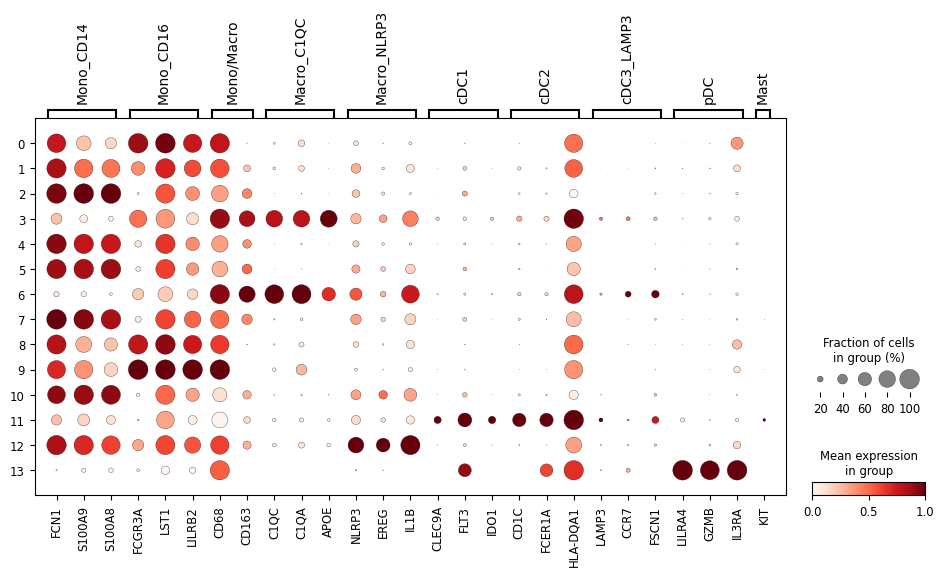

In [ ]:
import scanpy as sc

# 세포 유형별 대표 Marker gene
marker_genes = {
    "Mono_CD14":   ["FCN1", "S100A9", "S100A8"],    # Fig 1E
    "Mono_CD16":   ["FCGR3A", "LST1", "LILRB2"],    # Fig 1E
    "Mono/Macro":  ["CD68", "CD163"],               # Fig 1D
    "Macro_C1QC":  ["C1QC", "C1QA", "APOE"],        # Fig 1E
    "Macro_NLRP3": ["NLRP3", "EREG", "IL1B"],       # Fig 1E
    "cDC1":        ["CLEC9A", "FLT3", "IDO1"],      # Fig 1E
    "cDC2":        ["CD1C", "FCER1A", "HLA-DQA1"],  # Fig 1E, Fig 1D
    "cDC3_LAMP3":  ["LAMP3", "CCR7", "FSCN1"],      # Fig 1E
    "pDC":         ["LILRA4", "GZMB", "IL3RA"],     # Fig 1E, Fig 1D
    "Mast":        ["KIT", "TPSAB1", "CPA3"],       # Fig 1E, Fig 1D
}

tam_subsets = {   # 논문 TAM 아형
    "Macro_SPP1":  ["SPP1"],
    "Macro_C1QC":  ["C1QC"],
    "Macro_ISG15": ["ISG15"],
}

# 1. 데이터셋에 존재하는 유전자만 필터링하여 새로운 딕셔너리 생성
available_markers = {}
for cell_type, genes in marker_genes.items():
    available = [gene for gene in genes if gene in adata.var_names]
    if available:
        available_markers[cell_type] = available
        print(f"{cell_type} available markers: {available}")

# 2. 필터링된 딕셔너리를 통째로 전달하여 하나의 통합된 dotplot 생성
sc.pl.dotplot(
    adata,
    var_names=available_markers,
    groupby="leiden",
    standard_scale="var",
    use_raw=False,
    cmap="Reds" # 이미지와 비슷한 파랑-노랑-빨강 색상 맵 적용
)

In [ ]:
mast = ['KIT', 'TPSAB1', 'TPSB2', 'CPA3', 'MS4A2', 'HDC']
print('데이터에 있는 마스트 유전자:', [g for g in mast if g in adata.var_names])
print('KIT 발현 세포 수:', (adata[:, 'KIT'].X > 0).sum())

데이터에 있는 마스트 유전자: ['KIT']
KIT 발현 세포 수: 16


In [ ]:
import pandas as pd

annot_table = pd.DataFrame([
    ['2, 4, 5, 7, 10', 'Mono_CD14',                     'FCN1, S100A9, S100A8'],
    ['0, 8, 9',        'Mono_CD16',                     'FCGR3A, LST1, LILRB2'],
    ['1',              'Mono_CD14CD16 (중간형)',         'CD14·CD16 마커 둘 다 중간'],
    ['6',              'Macro_C1QC',                    'C1QC, C1QA, CD163'],
    ['3',              'Macro_C1QC (APOE 높은 쪽)',      'APOE, CD68, CD163, HLA-DQA1'],
    ['12',             'Macro_NLRP3',                   'NLRP3, EREG, IL1B'],
    ['11',             'cDC (cDC2 위주, cDC1 일부)',     'CD1C, FCER1A, HLA-DQA1'],
    ['13',             'pDC',                           'LILRA4, GZMB, IL3RA'],
    ['-',              'Mast (없음)',                    'KIT 거의 0'],
], columns=['클러스터', '세포 유형', '가장 진한 마커'])

# 클러스터별 세포 수 합치기
counts = adata.obs['leiden'].value_counts()
annot_table['세포 수'] = annot_table['클러스터'].apply(
    lambda s: sum(counts.get(c.strip(), 0) for c in s.split(',')))

annot_table

,클러스터,세포 유형,가장 진한 마커,세포 수
0,"2, 4, 5, 7, 10",Mono_CD14,"FCN1, S100A9, S100A8",2773
1,"0, 8, 9",Mono_CD16,"FCGR3A, LST1, LILRB2",2081
2,1,Mono_CD14CD16 (중간형),CD14·CD16 마커 둘 다 중간,1188
3,6,Macro_C1QC,"C1QC, C1QA, CD163",545
4,3,Macro_C1QC (APOE 높은 쪽),"APOE, CD68, CD163, HLA-DQA1",640
5,12,Macro_NLRP3,"NLRP3, EREG, IL1B",135
6,11,"cDC (cDC2 위주, cDC1 일부)","CD1C, FCER1A, HLA-DQA1",175
7,13,pDC,"LILRA4, GZMB, IL3RA",82
8,-,Mast (없음),KIT 거의 0,0
